# Analisis Sentimen Publik terhadap Raffi Ahmad

**Nama:** Raphael Angelo Adikara Purnama
**NIM:** 164241055
**Mata kuliah:** Natural Language Processing (UAS)
**Topik:** Klasifikasi sentimen publik terhadap Raffi Ahmad setelah kasus "mahasiswa bayaran" di Bundaran HI (29 Oktober 2026)

Notebook 02 sampai 05 membahas model. Notebook ini kembali ke pertanyaan awalnya: bagaimana sikap warganet ke Raffi setelah kasus ini, dan apakah masih ada yang membelanya. Yang dipakai di sini adalah label akhir (sepakat bulat 3 AI atau suara terbanyak 3 orang), bukan tebakan model, karena labelnya sudah dicek manusia dan lebih bisa dipercaya daripada model terbaik yang macro-F1-nya masih di bawah 0,7.

Ada tiga kelompok teks yang dianalisis terpisah:

1. **Jalur A (data utama):** komentar di unggahan berita dan kreator, bukan buzzer. Ini dasar semua angka utama.
2. **Jalur B:** komentar di akun Instagram Raffi sendiri. Kelompok ini tidak dipakai untuk training (kecuali positifnya untuk augmentasi), karena yang berkomentar di akun seseorang cenderung penggemarnya. Justru karena itu menarik dilihat apakah di akunnya sendiri dia masih dibela.
3. **Buzzer hasil review:** teks yang menurut tim bunyinya seperti pesan pesanan. Dilaporkan terpisah dan tidak ikut di angka utama.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import chi2_contingency

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path.cwd().parent
FIG = ROOT / "figures"
SENT = ["negatif", "netral", "positif"]
WARNA = {"negatif": "#c0504d", "netral": "#9aa5b1", "positif": "#4f81bd"}

s = pd.read_csv(ROOT / "data" / "05_final" / "semua_label.csv", parse_dates=["tanggal"])
s["aspek"] = s.aspek.fillna("umum")
a = s[(s.kelompok == "utama") & ~s.buzzer & s.label.isin(SENT)].copy()
b = s[(s.kelompok == "jalur_b") & ~s.buzzer & s.label.isin(SENT)].copy()
bz = s[s.buzzer].copy()
print("jalur A:", len(a), "| jalur B:", len(b), "| buzzer hasil review:", len(bz),
      "| tidak relevan (dibuang):", int(s.label.eq("tidak_relevan").sum()))
pd.DataFrame({"jalur A": a.label.value_counts(), "jalur B": b.label.value_counts()}).reindex(SENT).assign(
    **{"jalur A (%)": lambda x: (x["jalur A"] / x["jalur A"].sum() * 100).round(1),
       "jalur B (%)": lambda x: (x["jalur B"] / x["jalur B"].sum() * 100).round(1)})

jalur A: 3329 | jalur B: 514 | buzzer hasil review: 14 | tidak relevan (dibuang): 193


,jalur A,jalur B,jalur A (%),jalur B (%)
label,,,,
negatif,2205,401,66.2,78.0
netral,1040,71,31.2,13.8
positif,84,42,2.5,8.2


Jalur A berisi 3.329 teks: 2.205 negatif (66,2%), 1.040 netral (31,2%), dan hanya 84 positif (2,5%). Jadi dari setiap 40 komentar tentang kasus ini, kira-kira hanya satu yang membela atau mendukung Raffi. Sebanyak 193 teks dibuang karena tidak relevan, dan 14 teks dipisah sebagai buzzer.

Jalur B (akun Raffi sendiri) berisi 514 teks, dan hasilnya di luar dugaan saya. Positifnya memang lebih tinggi (8,2%), tapi negatifnya juga lebih tinggi, yaitu 78,0%. Bagian ini dibahas lagi di bawah.

## Sentimen per fase

Fase dibagi tiga: **pra** (22 sampai 28 Oktober), **puncak** (29 Oktober sampai 2 November, dari deklarasi sampai GSI Youth Fest batal mengundang Raffi), dan **pasca** (3 sampai 14 November, termasuk temuan ICW soal kontrak Rp14,7 miliar). Uji chi-square dipakai untuk melihat apakah perbedaan proporsi antarfase lebih besar dari yang bisa terjadi karena kebetulan.

In [2]:
ct = pd.crosstab(a.fase, a.label).reindex(["pra", "puncak", "pasca"])[SENT]
persen = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
display(ct.assign(total=ct.sum(axis=1)).join(persen, rsuffix=" (%)"))
chi2, p, dof, _ = chi2_contingency(ct.loc[["puncak", "pasca"]])
print(f"puncak vs pasca: chi2 = {chi2:.2f}, dof = {dof}, p = {p:.4f}")

label,negatif,netral,positif,total,negatif (%),netral (%),positif (%)
fase,,,,,,,
pra,17,12,1,30,56.7,40.0,3.3
puncak,1002,549,36,1587,63.1,34.6,2.3
pasca,1186,479,47,1712,69.3,28.0,2.7


puncak vs pasca: chi2 = 16.99, dof = 2, p = 0.0002


Fase pra hanya punya 30 teks, karena sebelum 29 Oktober Raffi belum dikaitkan dengan kasus apa pun dan hampir tidak ada komentar yang lolos filter relevansi. Karena itu perbandingan yang bisa dipercaya hanya puncak dan pasca.

Negatif naik dari 63,1% di fase puncak menjadi 69,3% di fase pasca, sedangkan positif tetap kecil (2,3% lalu 2,7%). Uji chi-square memberi p = 0,0002, jadi kenaikan negatif ini bukan kebetulan. Artinya, setelah klarifikasi Raffi, sikap warganet tidak melunak. Justru makin negatif setelah muncul isu kontrak Rp14,7 miliar.

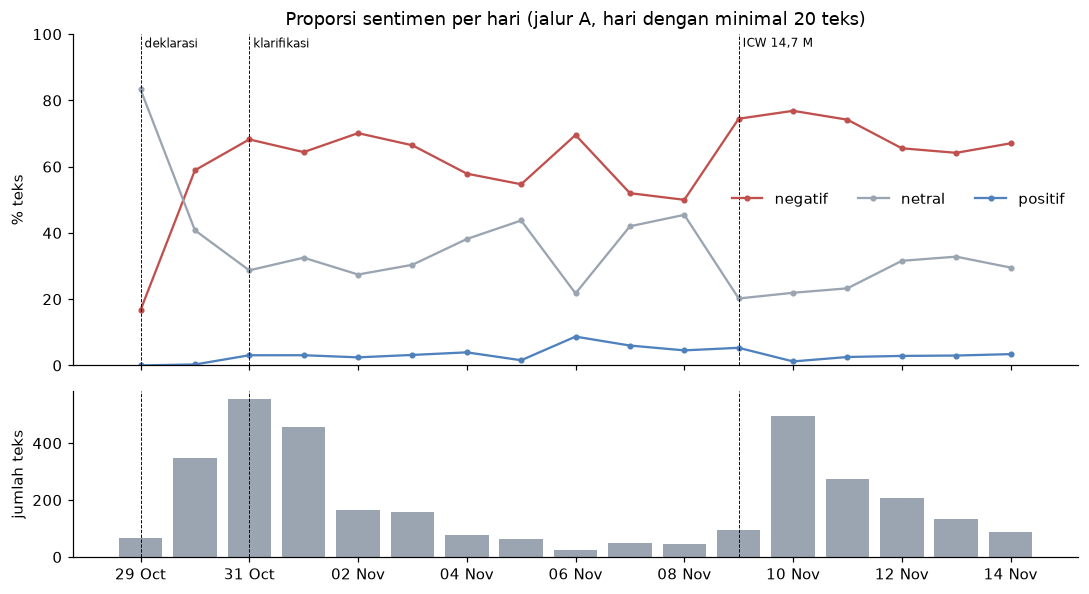

In [3]:
harian = a.groupby([a.tanggal.dt.date, "label"]).size().unstack(fill_value=0).reindex(columns=SENT, fill_value=0)
harian = harian[harian.sum(axis=1) >= 20]  # hari dengan < 20 teks terlalu sedikit untuk dihitung proporsinya
prop = harian.div(harian.sum(axis=1), axis=0)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for c in SENT:
    ax1.plot(prop.index, prop[c] * 100, marker="o", ms=3, color=WARNA[c], label=c)
ax1.set(ylabel="% teks", title="Proporsi sentimen per hari (jalur A, hari dengan minimal 20 teks)")
ax1.legend(frameon=False, ncol=3)
ax2.bar(harian.index, harian.sum(axis=1), color="#9aa5b1")
ax2.set(ylabel="jumlah teks")
for ax in (ax1, ax2):
    for t, nama in [("2026-10-29", "deklarasi"), ("2026-10-31", "klarifikasi"), ("2026-11-09", "ICW 14,7 M")]:
        ax.axvline(pd.Timestamp(t).date(), color="k", lw=0.6, ls="--")
        if ax is ax1:
            ax.text(pd.Timestamp(t).date(), 99, " " + nama, fontsize=8, va="top")
ax1.set_ylim(0, 100)
import matplotlib.dates as mdates
ax2.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout()
plt.savefig(FIG / "06_tren_harian.png", bbox_inches="tight")
plt.show()

Ada tiga hal yang terlihat dari grafik.

1. **29 Oktober (hari deklarasi) netralnya 83,3%.** Di hari itu yang diejek adalah peserta yang mengaku dibayar. Dari 66 teks hari itu, 34 punya target_lain mahasiswa_bayaran. Raffi belum menjadi sasaran.
2. **Sasaran pindah ke Raffi mulai 30 dan 31 Oktober.** Negatif naik ke 58,9% lalu 68,2%. 31 Oktober adalah hari klarifikasi dan hari dengan teks terbanyak (554). Klarifikasinya tidak meredam, malah jadi bahan baru.
3. **Puncak kedua setelah ICW (9 November).** Negatif mencapai 74,5% sampai 76,9% di 9 sampai 11 November, tertinggi di seluruh periode, dengan 497 teks di 10 November.

Positif tidak pernah lebih dari 9%. Angka tertingginya 8,7% di 6 November, tapi hari itu hanya ada 23 teks, jadi itu hanya 2 teks.

## Sentimen per platform

In [4]:
ct = pd.crosstab(a.platform, a.label)[SENT]
display(ct.assign(total=ct.sum(axis=1)).join((ct.div(ct.sum(axis=1), axis=0) * 100).round(1), rsuffix=" (%)"))
chi2, p, dof, _ = chi2_contingency(ct)
print(f"antarplatform: chi2 = {chi2:.2f}, dof = {dof}, p = {p:.2e}")

label,negatif,netral,positif,total,negatif (%),netral (%),positif (%)
platform,,,,,,,
instagram,544,308,15,867,62.7,35.5,1.7
tiktok,371,87,30,488,76.0,17.8,6.1
x,786,457,23,1266,62.1,36.1,1.8
youtube,504,188,16,708,71.2,26.6,2.3


antarplatform: chi2 = 92.57, dof = 6, p = 8.87e-18


Perbedaan antarplatform signifikan (p sekitar 9 × 10⁻¹⁸). TikTok paling negatif (76,0%) sekaligus paling positif (6,1%), jadi komentar di TikTok paling terbelah. Instagram dan X paling banyak netral (sekitar 36%), karena di sana banyak komentar yang mengejek mahasiswa bayaran atau pemerintah tanpa menyebut Raffi. YouTube 71,2% negatif.

## Apa yang dibahas

Setiap teks punya kolom aspek dari labeling (boleh lebih dari satu): mahasewa, klarifikasi, jabatan utusan khusus, kontrak Rp14,7 miliar, boikot RANS, kehidupan pribadi, atau umum. Tabel ini menghitung berapa persen teks negatif di setiap aspek dan bagaimana porsinya berubah dari fase puncak ke pasca.

In [5]:
asp = a.assign(aspek=a.aspek.str.split(";")).explode("aspek").reset_index(drop=True)
t = asp.groupby("aspek").agg(n=("id", "size"), negatif=("label", lambda x: (x == "negatif").mean() * 100),
                             positif=("label", lambda x: (x == "positif").mean() * 100)).round(1)
porsi = (pd.crosstab(asp.aspek, asp.fase, normalize="columns") * 100).round(1)[["puncak", "pasca"]]
t.join(porsi.add_prefix("porsi di fase ")).sort_values("n", ascending=False)

,n,negatif,positif,porsi di fase puncak,porsi di fase pasca
aspek,,,,,
umum,1055,66.2,2.9,32.0,26.8
kontrak_14m,837,77.5,1.9,1.9,42.9
mahasewa,563,40.3,0.9,29.1,4.1
boikot_rans,429,67.4,0.9,17.6,7.2
jabatan_utusan,311,80.1,3.2,8.2,9.0
klarifikasi,218,76.6,5.5,9.3,3.3
kehidupan_pribadi,164,69.5,4.9,2.0,6.7


Aspek yang paling negatif adalah jabatan utusan khusus (80,1%), kontrak Rp14,7 miliar (77,5%), dan klarifikasi (76,6%). Aspek mahasewa justru paling rendah negatifnya (40,3%), karena komentar soal mahasewa lebih sering mengejek pesertanya daripada Raffi.

Porsi aspek berubah jelas antarfase. Di fase puncak, kontrak Rp14,7 miliar hanya 1,9% dari aspek yang dibahas, sedangkan di fase pasca naik menjadi 42,9% dan menjadi topik utama. Sebaliknya, mahasewa turun dari 29,1% menjadi 4,1%, dan boikot RANS dari 17,6% menjadi 7,2%. Jadi kasus deklarasi cepat dilupakan, lalu diganti isu yang lebih berat, yaitu uang negara.

## Siapa yang masih membela

Teks positif dibagi tiga sub-kategori di codebook: **membela** (dengan argumen, misalnya "dia cuma diundang"), **simpati** (kasihan), dan **dukungan** (pujian atau doa tanpa argumen). Sub-kategori negatif juga ditampilkan supaya kelihatan bentuk kritiknya.

In [6]:
sub = pd.crosstab(a["sub"].fillna("(tidak diisi)"), a.label)[SENT]
display(sub[sub.sum(axis=1) > 0].sort_values(SENT, ascending=False))
print("contoh teks positif (jalur A):")
display(a[a.label == "positif"].sample(10, random_state=3)[["platform", "fase", "sub", "text"]])

label,negatif,netral,positif
sub,,,
kritik,890,16,0
sindiran,719,20,0
boikot,276,3,0
hinaan,216,1,0
(tidak diisi),69,43,2
lainnya,28,678,1
pertanyaan,6,63,0
informasi,1,214,1
membela,0,2,42


contoh teks positif (jalur A):


,platform,fase,sub,text
3471,instagram,pasca,membela,lagian kalo artis sekelas raffi masuk ke kerumunan massa ya malah bikin rusuh dan ga kondusif
4001,youtube,puncak,membela,"Jujur kalau masalah menghujat dan menghakimi netizen Indonesia nomor satu, yang suka membenci provokator fitnah siri..."
881,instagram,pasca,membela,"Lah kocak, ini ma kerjasama biasa aja diperusahaan.. dikira gratis kali wkwkw.. Promo2 wisata di yt rans yg the duda..."
3004,youtube,puncak,dukungan,"*SEMOGA RAFFI AHMAD SEKELUARGA SELALU DIDALAM LINDUNGAN DAN KEBERKAHAN ALLAH SWT, AAMIIN..*"
1377,tiktok,pasca,membela,saya tidak percaya berita hoax kaya gini 😜😜😜😜.. saya peecya AA Rafi bukan orang kaya gituu 👏🏻👏🏻👏🏻. orang yang sering...
3832,x,pasca,membela,"@user Karena nilainya rendah, makanya enak ngomongnya. 🗣️Rans, the dudas Raffi, Desta, Gading dan Boril 14M woi.... ..."
4003,youtube,pasca,membela,"Saya mikirnya justru 14 M ini adalah reward yang di kemas dalam bentuk kerjaan profesional , secara RA timses 02 pil..."
2894,youtube,puncak,dukungan,Terus buat kebaikan selalu Sukses
3594,tiktok,puncak,simpati,hnya Krn beda pilihan 😭
468,instagram,puncak,membela,Dia memang di undang kan shari sblumnya...mnrt sy yg dipersalahkan yg buat acarany...klo yg diundang disalahkan mnrt...


Dari 84 teks positif di jalur A, sebagian besar adalah **membela** dengan argumen (42), sisanya dukungan (22) dan simpati (16). Contohnya: "Dia memang di undang kan shari sblumnya...mnrt sy yg dipersalahkan yg buat acarany..." dan "Lah kocak, ini ma kerjasama biasa aja diperusahaan". Jadi pembelanya ada, tapi jumlahnya sangat sedikit, dan argumennya berulang: Raffi hanya diundang, dan kontrak itu kerja sama biasa.

Bentuk negatifnya kebanyakan kritik dengan alasan (890) dan sindiran (719), sedangkan hinaan kasar hanya 216. Ajakan boikot ada 276 teks. Ada 114 teks yang sub-kategorinya tidak diisi karena labeling AI menganggapnya tidak relevan, sedangkan reviewer manusia menilainya relevan.

## Akun Raffi sendiri (jalur B)

Komentar jalur B diambil dari unggahan akun Instagram Raffi di rentang waktu yang sama. Dugaan awal saya, kelompok ini akan jauh lebih positif karena yang berkomentar di akun seseorang biasanya pengikutnya.

In [7]:
ct = pd.DataFrame({"jalur A (IG)": a[a.platform == "instagram"].label.value_counts(),
                   "jalur B (akun Raffi)": b.label.value_counts()}).reindex(SENT)
display(ct.join((ct / ct.sum() * 100).round(1), rsuffix=" (%)"))
chi2, p, dof, _ = chi2_contingency(ct.T)
print(f"IG jalur A vs jalur B: chi2 = {chi2:.2f}, p = {p:.4f}")
print(pd.crosstab(b.fase, b.label)[SENT].to_string())
print("\ncontoh komentar negatif di akun Raffi:")
display(b[b.label == "negatif"].sample(8, random_state=1)[["fase", "text"]])

,jalur A (IG),jalur B (akun Raffi),jalur A (IG) (%),jalur B (akun Raffi) (%)
label,,,,
negatif,544,401,62.7,78.0
netral,308,71,35.5,13.8
positif,15,42,1.7,8.2


IG jalur A vs jalur B: chi2 = 98.86, p = 0.0000
label   negatif  netral  positif
fase                            
pasca       246      34       18
pra           5       3        0
puncak      150      34       24

contoh komentar negatif di akun Raffi:


,fase,text
497,pasca,"Mayan kenyang ya 14.7M lohhhh dari APBN, mantap kaliiii 😍😍😍"
1077,pasca,Minimal nyusul ngundurin diri fii
3245,pasca,3 M kurang lebih
312,pasca,"14M wok. Misal dipake 5juta aja perbulan, bisa ngidupin 233 keluarga sampe setahun. Buset buset"
230,puncak,"Ngapain dtg bareng MAHASEWA, Salah hari @user Mustinya tgl 28 Okt 👎🏻 Kedatanganmu justru memberi support pada sisi y..."
538,pasca,"Omongan nya rapi , penampilan rapi, semua rapi, cuciannya rapi gak ???"
3215,pasca,Komen orang orang ilang ya??
808,pasca,😀 pola nya tiap ada mslh pst mejeng foto keluarga


Dugaan saya salah. Di akun Instagram Raffi sendiri, 78,0% komentar negatif, lebih tinggi dari Instagram jalur A (62,7%). Perbedaannya signifikan (p < 0,0001). Positifnya memang lebih banyak (8,2% lawan 1,7%), tapi jumlahnya hanya 42 teks. Contoh komentarnya: "Mayan kenyang ya 14.7M lohhhh dari APBN, mantap kaliiii" dan "Minimal nyusul ngundurin diri fii". Kelihatannya warganet sengaja datang ke akun Raffi untuk menyampaikan kritik secara langsung, jadi kolom komentar akunnya bukan lagi tempat penggemar saja.

Di fase pasca, 246 dari 298 komentar jalur B negatif (82,6%), dan hanya 18 positif.

## Buzzer

Teks yang ditandai buzzer oleh tim saat review tidak ikut di angka di atas. Yang ditampilkan di sini adalah sikap teks-teks itu, untuk melihat apakah buzzer yang tertangkap condong membela atau menyerang.

In [8]:
print(bz.groupby(["kelompok", "label"]).size().to_string())
bz[["platform", "label", "text"]]

kelompok  label  
utama     negatif    12
          positif     2


,platform,label,text
4026,instagram,negatif,"🇮🇩 RAKYAT INDONESIA, SAATNYA BERSUARA! Mari kita kritis dalam menilai para tokoh publik. Jangan sampai popularitas d..."
4027,x,negatif,"Raffi Ahmad akhirnya MUNCUL! Dia beberapa hari ini menghilang setelah perusahaannya diungkap menerima Rp14,7 miliar ..."
4028,x,negatif,"KAMI MENDUKUNG PENUH RAFFI AHMAD DKK DIPENJARAKAN DAN MEMINTA PERTANGGUNGJAWABAN ATAS PEMBOHONGAN PUBLIK, MEMBAYAR S..."
4029,x,negatif,Kami segenap warga indonesia mendukung penuh Raffi Ahmad dkk dipenjarakan dan diminta pertanggungjawaban atas pemboh...
4030,x,negatif,Peringatan darurat 🚨🚨🚨🚨 Gerakan #indonesiasadar “ intel berotak kosong diduga lakukan kekerasan dan penculikan pd de...
4034,x,negatif,Peringatan darurat 🚨🚨🚨🚨 Gerakan #indonesiasadar “ aku pendukung mbak - mbak nya “ Boikot Raffi Ahmad x RANS dan seka...
4035,x,negatif,"Peringatan darurat 🚨🚨🚨🚨 Gerakan #indonesiasadar “ Maguwo Jogja di boikot, Acara RANS carnival sepi, Guyon waton Masd..."
4036,x,negatif,"Peringatan darurat 🚨🚨🚨🚨 Gerakan #indonesiasadar “ Warga Jogja Keren, mereka sibuk antre UMKM yg mundur di RANS carni..."
4037,x,negatif,Peringatan darurat 🚨🚨🚨🚨 Gerakan #indonesiasadar “ kalau Raffi Ahmad bukan lalu Willie salim bukan terus siapa .??? M...
4039,x,negatif,Peringatan darurat 🚨🚨🚨🚨 Gerakan #indonesiasadar “ Udah November 2026 tapi kita tetap dihajar sama bocil yg sempak ny...


Dari 14 teks yang diputuskan buzzer oleh tim, 12 negatif dan hanya 2 positif. Polanya terlihat jelas: banyak yang dibuka dengan template "Peringatan darurat 🚨🚨🚨🚨 Gerakan #indonesiasadar" atau "KAMI MENDUKUNG PENUH RAFFI AHMAD DKK DIPENJARAKAN". Jadi buzzer yang tertangkap kebanyakan menyerang Raffi. Karena teks ini sudah dikeluarkan, proporsi negatif 66,2% di atas tidak dinaikkan oleh buzzer. Dua buzzer positif berisi pembelaan generik seperti "contoh nyata figur publik yang sukses merintis karir dari bawah".

## Sentimen yang ditimbang like

Satu komentar dengan 2.000 like mewakili lebih banyak orang daripada komentar tanpa like. Sebagai pembanding, proporsi sentimen juga dihitung dengan bobot 1 + jumlah like (supaya komentar tanpa like tetap terhitung satu). Angka ini hanya pelengkap, karena like juga dipengaruhi jam unggah dan posisi komentar.

In [9]:
a["like"] = pd.to_numeric(a.like_count, errors="coerce").fillna(0)
w = a.groupby("label").like.apply(lambda x: (1 + x).sum()).reindex(SENT)
pd.DataFrame({"tanpa bobot (%)": (a.label.value_counts(normalize=True).reindex(SENT) * 100).round(1),
              "bobot 1 + like (%)": (w / w.sum() * 100).round(1),
              "median like": a.groupby("label").like.median().reindex(SENT)})

,tanpa bobot (%),bobot 1 + like (%),median like
label,,,
negatif,66.2,65.1,7.0
netral,31.2,34.8,4.0
positif,2.5,0.2,2.0


Kalau ditimbang like, porsi negatif hampir sama (65,1%), netral naik sedikit (34,8%), tapi positif turun dari 2,5% menjadi 0,2%. Median like komentar positif hanya 2, sedangkan negatif 7. Jadi komentar yang membela Raffi bukan hanya sedikit, tapi juga jarang disetujui warganet lain.

## Kesimpulan

Pertanyaan awalnya adalah apakah masih ada yang membela Raffi. Jawabannya: ada, tapi sangat sedikit. Hanya 2,5% komentar jalur A yang positif, dan kalau ditimbang like porsinya hanya 0,2%.

- Sikap negatif tidak turun setelah klarifikasi. Negatif naik dari 63,1% (puncak) ke 69,3% (pasca), dan tertinggi di 9 sampai 11 November setelah temuan ICW soal kontrak Rp14,7 miliar.
- Topiknya bergeser. Di awal yang ramai dibahas adalah mahasiswa bayaran, dan sasarannya pesertanya, bukan Raffi. Setelah 9 November, kontrak Rp14,7 miliar menjadi 42,9% dari aspek yang dibahas.
- Akun Raffi sendiri tidak menjadi tempat berlindung. 78,0% komentar di sana negatif.
- Buzzer yang tertangkap kebanyakan menyerang (12 dari 14), dan sudah dikeluarkan dari angka utama.

Keterbatasannya, angka ini berasal dari sampel komentar yang di-scrape (sekitar 3.500 teks jalur A), bukan seluruh warganet, dan fase pra terlalu sedikit untuk dibandingkan. Label juga tidak sempurna: Fleiss' kappa 3 penilai di teks yang ambigu hanya 0,286, dan sebagian besar beda pendapat ada di batas negatif dan netral. Kalau batas itu bergeser, persentase negatif bisa berubah beberapa poin, tapi kesimpulan bahwa positif sangat kecil tidak berubah, karena positif adalah kategori dengan kesepakatan paling tinggi (kappa 0,581).